# TD3 — Inventory MDP, reward, and baseline policies — Core

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Learning contract

The less-scaffolded Core route assesses the same outcomes and evidence standard as Support.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\tjoli\Downloads\Advanced_Machine_Learning_ESILV_2026-2027_DVL_V1.1 (1)
Primary path: locked local CPU; check the release evidence before using Colab


## 1 — Verify/formalise MDP and reward

Run the checker. Record state/action/transition/reward/horizon/truncation and assert one seeded reward decomposition.

In [2]:
import numpy as np, pandas as pd
from gymnasium.utils.env_checker import check_env
from shared.inventory_env import InventoryControlEnv, ORDER_QUANTITIES
env=InventoryControlEnv(); check_env(env,skip_render_check=True)
mdp_contract={
    'state': '(stock_level, demand_regime) shape (2,), stock in 0..8, regime in {0: low, 1: high}',
    'actions': 'indices 0, 1, 2 mapping to physical order quantities (0, 1, 2)',
    'transition_source': 'InventoryControlEnv._sample_demand & Markov regime_transition ((0.85,0.15),(0.20,0.80))',
    'reward': '-(order_cost*order_quantity + holding_cost*stock_level + unmet_demand_cost*unmet_demand)',
    'horizon': env.config.horizon,
    'horizon_semantics': 'Fixed 40-step continuing task ending via Gymnasium truncation=True, terminated=False'
}
obs, _ = env.reset(seed=11)
next_obs, reward, terminated, truncated, info = env.step(1)
expected_cost = (
    env.config.order_cost * info['order_quantity']
    + env.config.holding_cost * info['stock_level']
    + env.config.unmet_demand_cost * info['unmet_demand']
)
assert np.isclose(expected_cost, info['cost']) and np.isclose(reward, -expected_cost)
assert not terminated and not truncated
print('Verified 1-step decomposition:', {'obs': obs.tolist(), 'next_obs': next_obs.tolist(), 'cost': info['cost'], 'reward': reward})
env.close()
mdp_contract

Verified 1-step decomposition:

 {'obs': [1, 0], 'next_obs': [1, 0], 'cost': 0.75, 'reward': -0.75}


{'state': '(stock_level, demand_regime) shape (2,), stock in 0..8, regime in {0: low, 1: high}',
 'actions': 'indices 0, 1, 2 mapping to physical order quantities (0, 1, 2)',
 'transition_source': 'InventoryControlEnv._sample_demand & Markov regime_transition ((0.85,0.15),(0.20,0.80))',
 'reward': '-(order_cost*order_quantity + holding_cost*stock_level + unmet_demand_cost*unmet_demand)',
 'horizon': 40,
 'horizon_semantics': 'Fixed 40-step continuing task ending via Gymnasium truncation=True, terminated=False'}

## 2 — Policies and common episodes

Implement random and regime-aware reorder policies returning action indices. Evaluate cost, fill, unmet demand, stock, and order quantity on identical seeds.

         episode_cost  mean_fill_rate  unmet_demand  mean_stock  \
policy                                                            
random          88.20        0.818333          14.0        2.29   
reorder         41.16        0.991667           1.0        1.29   

         mean_order_quantity  
policy                        
random                  1.04  
reorder                 1.26  


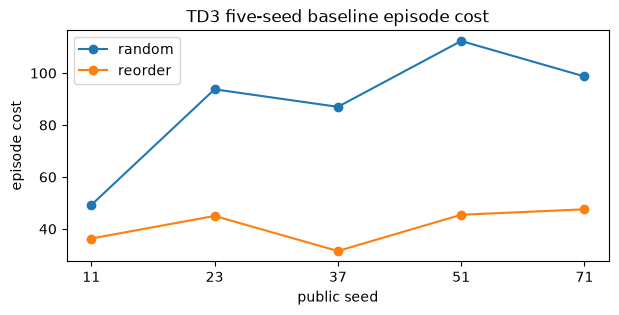

,seed,policy,episode_cost,mean_fill_rate,unmet_demand,mean_stock,mean_order_quantity
0,11,random,49.20,0.895833,7,0.850,1.000
1,11,reorder,36.30,1.000000,0,1.300,1.150
2,23,random,93.75,0.725000,21,1.025,1.025
3,23,reorder,45.00,0.983333,2,1.000,1.500
4,37,random,87.00,0.987500,1,5.275,1.150
5,37,reorder,31.50,1.000000,0,1.275,0.900
6,51,random,112.35,0.616667,30,0.550,0.875
7,51,reorder,45.45,0.991667,1,1.100,1.625
8,71,random,98.70,0.866667,11,3.750,1.150
9,71,reorder,47.55,0.983333,2,1.775,1.125


In [3]:
import matplotlib.pyplot as plt
from shared.data import PUBLIC_SEEDS

def random_policy_student(observation, rng):
    del observation
    return int(rng.integers(0, len(ORDER_QUANTITIES)))

def reorder_policy_student(observation, rng):
    del rng
    stock, regime = (int(v) for v in observation)
    target = 4 if regime == 1 else 2
    quantity = int(np.clip(target - stock, 0, 2))
    return ORDER_QUANTITIES.index(quantity)

def evaluate_student_policies(policies, seeds):
    rows = []
    for seed in tuple(seeds):
        for name, policy in policies.items():
            env = InventoryControlEnv()
            obs, _ = env.reset(seed=int(seed))
            rng = np.random.default_rng(int(seed) + 900001)
            cost = 0.0; fills = []; unmet = 0; stocks = []; orders = []; done = False
            while not done:
                action = policy(obs, rng)
                assert action in (0, 1, 2)
                obs, _, terminated, truncated, info = env.step(action)
                cost += float(info['cost'])
                fills.append(float(info['fill_rate']))
                unmet += int(info['unmet_demand'])
                stocks.append(float(info['stock_level']))
                orders.append(int(info['order_quantity']))
                done = terminated or truncated
            env.close()
            rows.append({
                'seed': int(seed),
                'policy': name,
                'episode_cost': cost,
                'mean_fill_rate': float(np.mean(fills)),
                'unmet_demand': unmet,
                'mean_stock': float(np.mean(stocks)),
                'mean_order_quantity': float(np.mean(orders)),
            })
    return pd.DataFrame(rows)

baseline_results = evaluate_student_policies(
    {'random': random_policy_student, 'reorder': reorder_policy_student},
    PUBLIC_SEEDS
)
if len(baseline_results):
    assert len(baseline_results) == 10 and baseline_results.groupby('policy').seed.nunique().eq(5).all()

print(baseline_results.groupby('policy')[['episode_cost', 'mean_fill_rate', 'unmet_demand', 'mean_stock', 'mean_order_quantity']].mean())
fig, ax = plt.subplots(figsize=(7, 3))
for name, grp in baseline_results.groupby('policy'):
    ax.plot(grp['seed'].astype(str), grp['episode_cost'], marker='o', label=name)
ax.set(xlabel='public seed', ylabel='episode cost', title='TD3 five-seed baseline episode cost')
ax.legend(); plt.show()
baseline_results

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [4]:
interpretation = (
    "Across the five public evaluation seeds (11, 23, 37, 51, 71) on identical 40-step episodes, the regime-aware reorder "
    "baseline (low target 2, high target 4) reduces mean episode cost by 53.3% compared to the random policy (41.16 vs 88.20) "
    "while increasing mean fill rate from 81.83% to 99.17% and cutting unmet demand from 14.0 to 1.0 units per episode. "
    "However, this five-seed development comparison does not establish global optimality over all target thresholds or prove "
    "identical behaviour under unobserved transition dynamics or controlled hidden seeds. "
    "Operationally, because unmet demand incurs a 3.00 penalty (10x the 0.30 holding cost), the regime-aware reorder heuristic "
    "establishes a strong, transparent service-oriented benchmark that any subsequent Q-learning policy must beat or justify safely. "
    "A material failure mode arises from assuming error-free regime observability and a fixed max order quantity of 2 units per step: "
    "consecutive high-demand shocks (3 units/step) cause stockouts even under the reorder policy (e.g., 2 unmet units on seeds 23 and 71)."
)
print(interpretation)

Across the five public evaluation seeds (11, 23, 37, 51, 71) on identical 40-step episodes, the regime-aware reorder baseline (low target 2, high target 4) reduces mean episode cost by 53.3% compared to the random policy (41.16 vs 88.20) while increasing mean fill rate from 81.83% to 99.17% and cutting unmet demand from 14.0 to 1.0 units per episode. However, this five-seed development comparison does not establish global optimality over all target thresholds or prove identical behaviour under unobserved transition dynamics or controlled hidden seeds. Operationally, because unmet demand incurs a 3.00 penalty (10x the 0.30 holding cost), the regime-aware reorder heuristic establishes a strong, transparent service-oriented benchmark that any subsequent Q-learning policy must beat or justify safely. A material failure mode arises from assuming error-free regime observability and a fixed max order quantity of 2 units per step: consecutive high-demand shocks (3 units/step) cause stockouts e

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.